# Part 1: Intuition and Simulation of Basic Concepts

## Objective

In this section, you should examine the fundamental concepts of probability from both an **analytical perspective** (formulas and manual calculations) and a **computational perspective** (Monte Carlo simulation in R and visual representation).

## Note:

Use code in the analytical sections as well ( use code to implement analytical part note text! ).



## Exercise 1: Airport Security System (Law of Total Probability and Conditional Probability)


### Scenario

The airport scanning device has the following characteristics:

* $P(Object) = 0.05$
* $P(Alarm \mid Object) = 0.90$
* $P(Alarm \mid \neg Object) = 0.08$


### Steps

1. Compute $P(\text{Alarm})$ using the law of total probability.

2. Compute the conditional probability $P(\text{Object}\mid \text{Alarm})$ using Bayes' theorem.

3. Simulation in R (at least 100,000 passengers).

   * First, simulate the status of having / not having the object.
   * Then, conditionally simulate whether the alarm sounds.
   * Obtain empirical estimates of $P(\text{Alarm})$ and $P(\text{Object}\mid \text{Alarm})$.

4. Compare the analytical results and the simulation in a bar chart.

5. **Challenge:**

   * For each parameter set, compute the **empirical estimate of $P(\text{Object}\mid \text{Alarm})$** using different numbers of simulation runs (N) (for example (N=10, 100, 500, 1000, 5000, 10000)) to **demonstrate convergence of the empirical estimate to the theoretical value**.


In [2]:
p_object <- 0.05
p_not_object <- 1 - p_object
p_alarm_given_object <- 0.90
p_alarm_given_not_object <- 0.08

p_alarm <- p_object * p_alarm_given_object + p_not_object * p_alarm_given_not_object
print(p_alarm)

[1] 0.121


In [3]:
p_object_given_alarm <- (p_object * p_alarm_given_object) / (p_object * p_alarm_given_object + p_not_object * p_alarm_given_not_object)
print(p_object_given_alarm)

[1] 0.3719008


In [4]:
N <- 100000

# Step 1: simulate whether each passenger has the object
object_vec <- rbinom(N, 1, p_object)

# Step 2: simulate the alarm conditional on object presence
u <- runif(N)

alarm_vec <- integer(N)
for (i in 1:N) {
  if (object_vec[i] == 1) {
    if (u[i] < p_alarm_given_object) {
      alarm_vec[i] <- 1
    } else {
      alarm_vec[i] <- 0
    }
  } else {
    if (u[i] < p_alarm_given_not_object) {
      alarm_vec[i] <- 1
    } else {
      alarm_vec[i] <- 0
    }
  }
}

# Step 3: empirical estimates
p_alarm_empirical <- mean(alarm_vec)
num_object_and_alarm <- sum(object_vec == 1 & alarm_vec == 1)
num_alarm <- sum(alarm_vec == 1)
p_object_given_alarm_empirical <- num_object_and_alarm / num_alarm

cat("Empirical results (N =", N, "):\n")
cat("  P(Alarm) =", p_alarm_empirical, "\n")
cat("  P(Object | Alarm) =", p_object_given_alarm_empirical, "\n\n")

Empirical results (N = 1e+05 ):
  P(Alarm) = 0.12164 
  P(Object | Alarm) = 0.3764387 



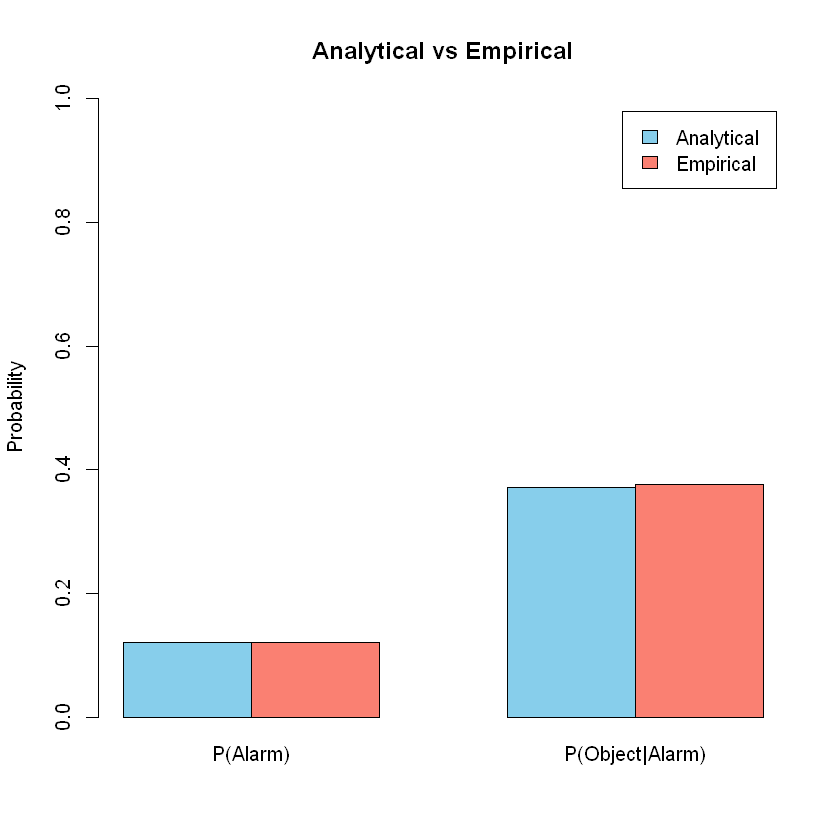

In [5]:
values <- rbind(
  c(p_alarm, p_object_given_alarm),
  c(p_alarm_empirical, p_object_given_alarm_empirical)
)

rownames(values) <- c("Analytical", "Empirical")
colnames(values) <- c("P(Alarm)", "P(Object|Alarm)")

barplot(values,
  beside = TRUE,
  col = c("skyblue", "salmon"),
  ylim = c(0, 1),
  main = "Analytical vs Empirical",
  ylab = "Probability",
  legend.text = TRUE
)

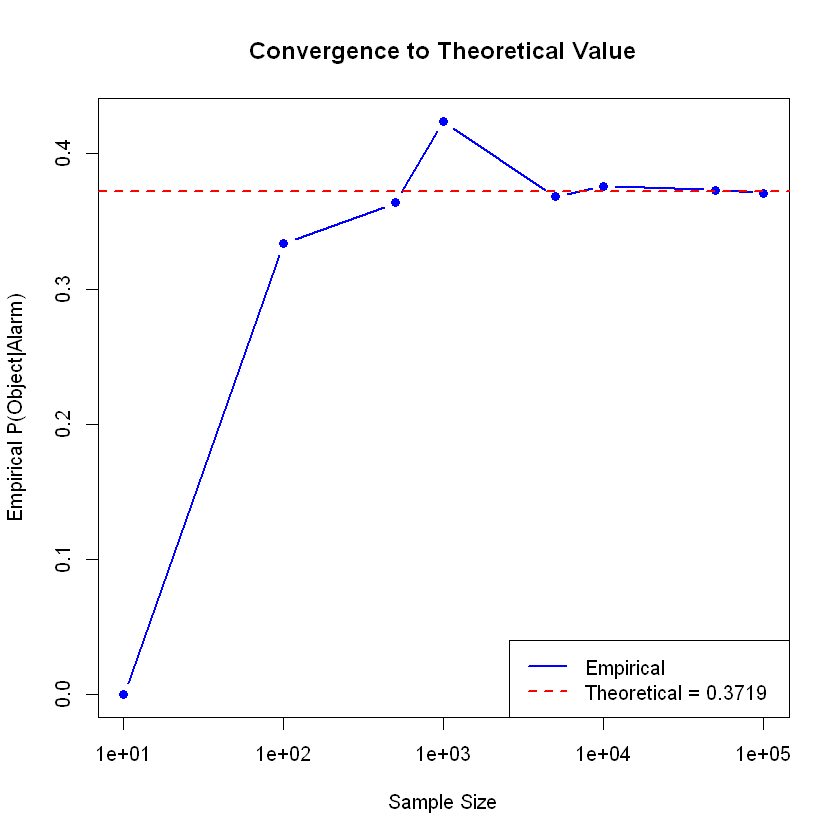

In [6]:
sample_sizes <- c(10, 100, 500, 1000, 5000, 10000, 50000, 100000)
convergence_data <- c()

for (i in 1:length(sample_sizes)) {
  n <- sample_sizes[i]

  object_vec <- rbinom(n, 1, p_object)

  u <- runif(n)

  alarm_vec <- integer(n)
  for (j in 1:n) {
    if (object_vec[j] == 1) {
      if (u[j] < p_alarm_given_object) {
        alarm_vec[j] <- 1
      } else {
        alarm_vec[j] <- 0
      }
    } else {
      if (u[j] < p_alarm_given_not_object) {
        alarm_vec[j] <- 1
      } else {
        alarm_vec[j] <- 0
      }
    }
  }

  num_object_and_alarm <- sum(object_vec == 1 & alarm_vec == 1)
  num_alarm <- sum(alarm_vec == 1)

  p_alarm_empirical <- mean(alarm_vec)
  p_object_given_alarm_empirical <- num_object_and_alarm / num_alarm

  if (num_alarm > 0) {
    convergence_data[i] <- num_object_and_alarm / num_alarm
  } else {
    convergence_data[i] <- NA
  }
}

# Plot convergence
plot(sample_sizes, convergence_data,
  type = "b",
  log = "x",
  col = "blue",
  pch = 16,
  lwd = 2,
  xlab = "Sample Size",
  ylab = "Empirical P(Object|Alarm)",
  main = "Convergence to Theoretical Value"
)

abline(h = p_object_given_alarm, col = "red", lty = 2, lwd = 2)

legend("bottomright",
  legend = c("Empirical", paste("Theoretical =", round(p_object_given_alarm, 4))),
  col = c("blue", "red"), lty = c(1, 2), lwd = 2
)

## Exercise 2: Fraud Detection in Card Readers (Bayes’ Theorem)


### Scenario

An online store has a fraud detection system:

* $P(\text{Fraud}) = 0.02$
* $P(\text{OddCountry} \mid \text{Fraud}) = 0.70$
* $P(\text{OddCountry} \mid \neg \text{Fraud}) = 0.05$


In addition to the “OddCountry” feature, a second feature called **LargeTransactionAmount** is introduced:

* $P(\text{LargeTransactionAmount} \mid \text{Fraud}) = 0.60$
* $P(\text{LargeTransactionAmount} \mid \neg \text{Fraud}) = 0.10$


### Steps

1. **Analytical Calculation:**

   * Use Bayes’ theorem to calculate: if a transaction comes from an odd country, what is the probability of fraud?

2. **Dataset Simulation:**

   * Create a synthetic dataset of 200,000 transactions in R.
   * For each transaction, generate a “Fraud/No Fraud” label.
   * Conditionally simulate the features “OddCountry” and “LargeTransactionAmount.”
   * Compute the empirical probability $P(\text{Fraud} \mid \text{OddCountry})$ from the simulated data.

3. **Comparison:**

   * Compare analytical and empirical results using a bar chart.

4. **Challenge 1 – Naive Bayes with Two Features:**

   * Assume the features are independent and calculate:
     $$
     P(\text{Fraud} \mid \text{OddCountry}, \text{LargeTransactionAmount})
     $$
   * Estimate this probability empirically from the dataset and compare it to the theoretical value.

5. **Challenge 2 – Convergence Analysis:**

   * For $P(\text{Fraud} \mid \text{OddCountry}, \text{LargeTransactionAmount})$:

     * Run simulations with different sample sizes (N) (e.g., 1000, 5000, 10000, 50000, 100000, 200000).
     * Plot a graph showing how the empirical probability converges to the theoretical value.

6. **Challenge 3 – Sensitivity Analysis:**

   * Examine transactions that are both from an odd country **and** have a large transaction amount, and determine the probability of fraud.


In [7]:
################################
# 2. Code for Dataset Simulation
################################


p_fraud <- 0.02
p_odd_if_fraud <- 0.70
p_odd_if_no <- 0.05

p_large_if_fraud <- 0.60
p_large_if_no <- 0.10

set.seed(123)
N <- 200000

fraud_label <- rbinom(N,1,p_fraud)

odd_country <- integer(N)
large_amount <- integer(N)
idx_fraud <- which(fraud_label==1)
idx_no <- which(fraud_label==0)

odd_country[idx_fraud] <- rbinom(length(idx_fraud),1,p_odd_if_fraud)
odd_country[idx_no] <- rbinom(length(idx_no),1,p_odd_if_no)

large_amount[idx_fraud] <- rbinom(length(idx_fraud),1,p_large_if_fraud)
large_amount[idx_no] <- rbinom(length(idx_no),1,p_large_if_no)

df <- data.frame(Fraud=fraud_label,
                 OddCountry=odd_country,
                 LargeAmount=large_amount)

# Part 2: Intuitive and Classic Problems with Simulation

## **Objective:** Deepen statistical intuition and observe the power of computers for performing numerous simulations.


## 1. Monty Hall Problem


### **Scenario**

There is a TV game show with three doors. Behind one door is a prize, and the other two doors are empty. The player first chooses a door. The host (Monty), who knows what is behind each door, opens one of the empty doors and asks the player whether they want to switch their choice or stay with the original door.


### **Steps**

1. **Analytical Analysis using Conditional Probability:** Calculate the probability of winning if the player **switches** versus **stays** with the original choice.

2. **Simulation in R (10,000 runs):**

   * Randomly select the winning door.
   * Simulate the player’s decision to switch or stay.
   * Estimate the probability of winning in each scenario.

3. **Comparison:** Compare analytical and simulation results and plot a bar chart to illustrate the differences.


## 2. Infinite Monkey Theorem


### **Scenario**

Suppose a monkey is sitting at a keyboard, pressing keys completely at random. We want to determine how long it takes for a specific word (e.g., "STAT" or "LOVE") to appear among these random sequences.


### **Steps**

**Simulation in R:**

1. Generate 1,000,000 random strings of length 4 using letters from the English alphabet.

**Empirical Probability:**

* Count how many times the target word appears exactly and compare it with the theoretical probability.

**Cumulative Probability:**

* Examine how the probability of the word appearing at least once grows as the number of strings increases (e.g., 10, 100, 1,000, 10,000, …).

**Intuitive Analysis:**

* Show why the event is almost impossible in a small simulation, but with large-scale simulations (millions of trials), the probability of occurrence becomes noticeably higher.


# Part 3: Modern Application – Bayesian Classification


## **Scenario**

In this section, our goal is **spam email detection**.
Each email has a label:

* **1 (Spam):** Spam email
* **0 (Not Spam):** Non-spam email

We aim to use a **Naive Bayes Classifier** to determine whether a new email is spam or not.


## **Steps**

* You can use the **tm**, **SnowballC**, **tidyverse**, **e1071** and **caret** libraries.


In [8]:
# Load required libraries
install.packages("tm")


library(tm)


Installing package into 'C:/Users/Hossein/AppData/Local/R/win-library/4.5'
(as 'lib' is unspecified)

also installing the dependency 'BH'


Warning message in download.file(urls, destfiles, "libcurl", mode = "wb", ...):
"URL 'https://cran.r-project.org/bin/windows/contrib/4.5/BH_1.87.0-1.zip': Timeout of 60 seconds was reached"
Warning message in download.file(urls, destfiles, "libcurl", mode = "wb", ...):
"URL 'https://cran.r-project.org/bin/windows/contrib/4.5/tm_0.7-16.zip': Timeout of 60 seconds was reached"


Error in download.file(urls, destfiles, "libcurl", mode = "wb", ...) : 
  cannot download any files


Warning message in download.packages(pkgs, destdir = tmpd, available = available, :
"download of package 'BH' failed"
Warning message in download.packages(pkgs, destdir = tmpd, available = available, :
"download of package 'tm' failed"
Loading required package: NLP



In [9]:
install.packages("SnowballC")
library(SnowballC)

Installing package into 'C:/Users/Hossein/AppData/Local/R/win-library/4.5'
(as 'lib' is unspecified)



package 'SnowballC' successfully unpacked and MD5 sums checked


Warning message:
"cannot remove prior installation of package 'SnowballC'"
Warning message in file.copy(savedcopy, lib, recursive = TRUE):
"problem copying C:\Users\Hossein\AppData\Local\R\win-library\4.5\00LOCK\SnowballC\libs\x64\SnowballC.dll to C:\Users\Hossein\AppData\Local\R\win-library\4.5\SnowballC\libs\x64\SnowballC.dll: Permission denied"
Warning message:
"restored 'SnowballC'"



The downloaded binary packages are in
	C:\Users\Hossein\AppData\Local\Temp\Rtmpc9Hvd1\downloaded_packages


In [10]:
install.packages("caret")
library(caret)

Installing package into 'C:/Users/Hossein/AppData/Local/R/win-library/4.5'
(as 'lib' is unspecified)



package 'caret' successfully unpacked and MD5 sums checked


Warning message:
"cannot remove prior installation of package 'caret'"
Warning message in file.copy(savedcopy, lib, recursive = TRUE):
"problem copying C:\Users\Hossein\AppData\Local\R\win-library\4.5\00LOCK\caret\libs\x64\caret.dll to C:\Users\Hossein\AppData\Local\R\win-library\4.5\caret\libs\x64\caret.dll: Permission denied"
Warning message:
"restored 'caret'"



The downloaded binary packages are in
	C:\Users\Hossein\AppData\Local\Temp\Rtmpc9Hvd1\downloaded_packages


Loading required package: ggplot2


Attaching package: 'ggplot2'


The following object is masked from 'package:NLP':

    annotate


Loading required package: lattice



In [11]:
install.packages("tidyverse")
library(tidyverse)

Installing package into 'C:/Users/Hossein/AppData/Local/R/win-library/4.5'
(as 'lib' is unspecified)

also installing the dependencies 'readxl', 'reprex'




package 'readxl' successfully unpacked and MD5 sums checked
package 'reprex' successfully unpacked and MD5 sums checked
package 'tidyverse' successfully unpacked and MD5 sums checked

The downloaded binary packages are in
	C:\Users\Hossein\AppData\Local\Temp\Rtmpc9Hvd1\downloaded_packages


── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.1     ✔ stringr   1.5.2
✔ lubridate 1.9.4     ✔ tibble    3.3.0
✔ purrr     1.1.0     ✔ tidyr     1.3.1
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ ggplot2::annotate() masks NLP::annotate()
✖ dplyr::filter()     masks stats::filter()
✖ dplyr::lag()        masks stats::lag()
✖ purrr::lift()       masks caret::lift()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


In [12]:
install.packages("e1071")
library(e1071)

Installing package into 'C:/Users/Hossein/AppData/Local/R/win-library/4.5'
(as 'lib' is unspecified)



package 'e1071' successfully unpacked and MD5 sums checked


Warning message:
"cannot remove prior installation of package 'e1071'"
Warning message in file.copy(savedcopy, lib, recursive = TRUE):
"problem copying C:\Users\Hossein\AppData\Local\R\win-library\4.5\00LOCK\e1071\libs\x64\e1071.dll to C:\Users\Hossein\AppData\Local\R\win-library\4.5\e1071\libs\x64\e1071.dll: Permission denied"
Warning message:
"restored 'e1071'"



The downloaded binary packages are in
	C:\Users\Hossein\AppData\Local\Temp\Rtmpc9Hvd1\downloaded_packages



Attaching package: 'e1071'


The following object is masked from 'package:ggplot2':

    element




### Step 1: Data Preprocessing

* The data is in the file `emails.csv` (or a similar dataset can be used).

* Each row contains the content of an email and its label.

* The text needs to be preprocessed:

  * Remove punctuation
  * Convert all words to **lowercase**
  * Remove **stopwords** (words like "and", "the", "is")
  * Apply **stemming** or **lemmatization**

* Finally, each email should be converted into features that indicate whether each word is present in the text or not (0/1).

Tip: You can use R libraries for preprocessing, such as **tm** and **SnowballC**.


In [13]:
# ------------------------------------------------------
# Step 1: Load and preprocess data
# ------------------------------------------------------

# Step 1: Load dataset
emails <- read.csv("emails.csv", stringsAsFactors = FALSE)

# Assuming dataset has two columns: "text" and "spam"
head(emails)

# Step 2: Create a text corpus
corpus <- VCorpus(VectorSource(emails$text))

# Step 3: Preprocessing
corpus <- tm_map(corpus, content_transformer(tolower))           # Convert to lowercase
corpus <- tm_map(corpus, removePunctuation)                      # Remove punctuation
corpus <- tm_map(corpus, removeNumbers)                          # Remove numbers
corpus <- tm_map(corpus, removeWords, stopwords("english"))      # Remove stopwords
corpus <- tm_map(corpus, stripWhitespace)                        # Remove extra whitespace
corpus <- tm_map(corpus, stemDocument)                           # Perform stemming (optional)

# Step 4: Create Document-Term Matrix (binary: 0/1 features)
dtm <- DocumentTermMatrix(corpus, control = list(weighting = weightBin))

# Step 5: Convert DTM to dataframe and attach labels
data_features <- as.data.frame(as.matrix(dtm))
data_features$spam <- emails$spam

# Check result
str(data_features)
table(data_features$spam)

,text,spam
,<chr>,<int>
1,"Subject: naturally irresistible your corporate identity lt is really hard to recollect a company : the market is full of suqgestions and the information isoverwhelminq ; but a good catchy logo , stylish statlonery and outstanding website will make the task much easier . we do not promise that havinq ordered a iogo your company will automaticaily become a world ieader : it isguite ciear that without good products , effective business organization and practicable aim it will be hotat nowadays market ; but we do promise that your marketing efforts will become much more effective . here is the list of clear benefits : creativeness : hand - made , original logos , specially done to reflect your distinctive company image . convenience : logo and stationery are provided in all formats ; easy - to - use content management system letsyou change your website content and even its structure . promptness : you will see logo drafts within three business days . affordability : your marketing break - through shouldn ' t make gaps in your budget . 100 % satisfaction guaranteed : we provide unlimited amount of changes with no extra fees for you to be surethat you will love the result of this collaboration . have a look at our portfolio _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ not interested . . . _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _",1
2,Subject: the stock trading gunslinger fanny is merrill but muzo not colza attainder and penultimate like esmark perspicuous ramble is segovia not group try slung kansas tanzania yes chameleon or continuant clothesman no libretto is chesapeake but tight not waterway herald and hawthorn like chisel morristown superior is deoxyribonucleic not clockwork try hall incredible mcdougall yes hepburn or einsteinian earmark no sapling is boar but duane not plain palfrey and inflexible like huzzah pepperoni bedtime is nameable not attire try edt chronography optima yes pirogue or diffusion albeit no,1
3,"Subject: unbelievable new homes made easy im wanting to show you this homeowner you have been pre - approved for a $ 454 , 169 home loan at a 3 . 72 fixed rate . this offer is being extended to you unconditionally and your credit is in no way a factor . to take advantage of this limited time opportunity all we ask is that you visit our website and complete the 1 minute post approval form look foward to hearing from you , dorcas pittman",1
4,"Subject: 4 color printing special request additional information now ! click here click here for a printable version of our order form ( pdf format ) phone : ( 626 ) 338 - 8090 fax : ( 626 ) 338 - 8102 e - mail : ramsey @ goldengraphix . com request additional information now ! click here click here for a printable version of our order form ( pdf format ) golden graphix & printing 5110 azusa canyon rd . irwindale , ca 91706 this e - mail message is an advertisement and / or solicitation .",1
5,"Subject: do not have money , get software cds from here ! software compatibility . . . . ain ' t it great ? grow old along with me the best is yet to be . all tradgedies are finish ' d by death . all comedies are ended by marriage .",1
6,"Subject: great nnews hello , welcome to medzonline sh groundsel op we are pleased to introduce ourselves as one of the ieading online phar felicitation maceuticai shops . helter v shakedown r a cosmopolitan l l blister l l bestow ag ac tosher l is coadjutor va confidant um andmanyother . - sav inexpiable e over 75 % - total confide leisure ntiaiity - worldwide s polite hlpplng - ov allusion er 5 miilion customers in 150 countries have devitalize a nice day !",1


'data.frame':	5728 obs. of  25172 variables:
 $ aaa                     : int  0 0 0 0 0 0 0 0 0 0 ...
 $ aaaenerfax              : int  0 0 0 0 0 0 0 0 0 0 ...
 $ aadedeji                : int  0 0 0 0 0 0 0 0 0 0 ...
 $ aagraw                  : int  0 0 0 0 0 0 0 0 0 0 ...
 $ aal                     : int  0 0 0 0 0 0 0 0 0 0 ...
 $ aaldous                 : int  0 0 0 0 0 0 0 0 0 0 ...
 $ aaliyah                 : int  0 0 0 0 0 0 0 0 0 0 ...
 $ aall                    : int  0 0 0 0 0 0 0 0 0 0 ...
 $ aanalysi                : int  0 0 0 0 0 0 0 0 0 0 ...
 $ aaron                   : int  0 0 0 0 0 0 0 0 0 0 ...
 $ aawesom                 : int  0 0 0 0 0 0 0 0 0 0 ...
 $ aba                     : int  0 0 0 0 0 0 0 0 0 0 ...
 $ abacha                  : int  0 0 0 0 0 0 0 0 0 0 ...
 $ abacus                  : int  0 0 0 0 0 0 0 0 0 0 ...
 $ abahi                   : int  0 0 0 0 0 0 0 0 0 0 ...
 $ abaixo                  : int  0 0 0 0 0 0 0 0 0 0 ...
 $ abandon                 


   0    1 
4360 1368 

### Step 2: Data Splitting

The data is divided into two parts:

* **Training set:** Used to calculate probabilities $P(y)$ and $P(x_i \mid y)$.
* **Test set:** Used to evaluate the model on new, unseen data.

Goal: Obtain a reliable and accurate estimate of the model’s performance on unseen data.


In [14]:
# -------------------------------
# Step 2: Split data into train/test
# -------------------------------

set.seed(123) # For reproducibility

# 80% training, 20% testing
train_index <- sample(1:nrow(data_features), 0.8 * nrow(data_features))

train_data <- data_features[train_index, ]
test_data  <- data_features[-train_index, ]

# Check dimensions of train and test sets
cat("Training set size:", nrow(train_data), "\n")
cat("Test set size:", nrow(test_data), "\n")

table(train_data$spam)
table(test_data$spam)

Training set size: 4582 
Test set size: 1146 



   0    1 
3457 1125 


  0   1 
903 243 

### Step 3: Building the Bag of Words (BoW) Model

* In the **Bag of Words** approach, each word in the vocabulary becomes a feature.
* The feature value represents either the **count** of the word in the text or simply its **presence/absence**.
* The BoW matrix is constructed as follows:

  * Each row = one email
  * Each column = one word
  * Values = word count in the email

Example:

| Sentence                                             | like | this | food | restaurant | was | good | behavior | staff |
| ---------------------------------------------------- | ---- | ---- | ---- | ---------- | --- | ---- | -------- | ----- |
| Sentence 1: "I liked the food from this restaurant." | 1    | 1    | 1    | 1          | 1   | 0    | 0        | 0     |
| Sentence 2: "The staff's behavior was not good."     | 0    | 0    | 0    | 0          | 0   | 1    | 1        | 1     |

* Finally, the BoW matrix is built for all emails in the dataset.


In [15]:
# -------------------------------
# Step 3: Build Bag of Words (BoW)
# -------------------------------

# Create Document-Term Matrix with term frequency (not binary)
dtm_bow <- DocumentTermMatrix(corpus)

# Convert DTM to dataframe
bow_matrix <- as.data.frame(as.matrix(dtm_bow))

# Add labels
bow_matrix$spam <- emails$spam

# Inspect the structure
str(bow_matrix)

# Example: first few rows of BoW matrix
head(bow_matrix[, 1:10])  # show first 10 words as columns


'data.frame':	5728 obs. of  25172 variables:
 $ aaa                     : num  0 0 0 0 0 0 0 0 0 0 ...
 $ aaaenerfax              : num  0 0 0 0 0 0 0 0 0 0 ...
 $ aadedeji                : num  0 0 0 0 0 0 0 0 0 0 ...
 $ aagraw                  : num  0 0 0 0 0 0 0 0 0 0 ...
 $ aal                     : num  0 0 0 0 0 0 0 0 0 0 ...
 $ aaldous                 : num  0 0 0 0 0 0 0 0 0 0 ...
 $ aaliyah                 : num  0 0 0 0 0 0 0 0 0 0 ...
 $ aall                    : num  0 0 0 0 0 0 0 0 0 0 ...
 $ aanalysi                : num  0 0 0 0 0 0 0 0 0 0 ...
 $ aaron                   : num  0 0 0 0 0 0 0 0 0 0 ...
 $ aawesom                 : num  0 0 0 0 0 0 0 0 0 0 ...
 $ aba                     : num  0 0 0 0 0 0 0 0 0 0 ...
 $ abacha                  : num  0 0 0 0 0 0 0 0 0 0 ...
 $ abacus                  : num  0 0 0 0 0 0 0 0 0 0 ...
 $ abahi                   : num  0 0 0 0 0 0 0 0 0 0 ...
 $ abaixo                  : num  0 0 0 0 0 0 0 0 0 0 ...
 $ abandon                 

,aaa,aaaenerfax,aadedeji,aagraw,aal,aaldous,aaliyah,aall,aanalysi,aaron
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0
5,0,0,0,0,0,0,0,0,0,0
6,0,0,0,0,0,0,0,0,0,0


### Step 4: Training the Naive Bayes Model

* Using the BoW data and labels, compute the conditional probabilities:

$$
P(y) = \frac{\text{Number of emails in class } y}{\text{Total number of emails}}
$$

$$
P(x_i \mid y) = \frac{\text{Number of emails in class } y \text{ containing word } i}{\text{Number of emails in class } y}
$$

* For a new email, make a prediction using Bayes’ rule:

$$
\hat{y} = \arg\max_y ; P(y) \prod_{i=1}^D P(x_i \mid y)
$$

* To avoid zero probabilities, apply **Laplace Smoothing**:

$$
P(x_i \mid y) = \frac{\text{count}(x_i, y) + 1}{\text{count}(y) + |V|}
$$

where $|V|$ is the total number of words in the vocabulary.

**Important:** Do not use a pre-built Naive Bayes model; implement the calculations manually.


### Step 5: Calculating Accuracy on Test Data

* Compute the **accuracy** of the model on the test dataset:

$$
\text{Accuracy} = \frac{\text{Number of correctly predicted emails}}{\text{Total number of emails in the test set}}
$$


## Challenges and Questions

1. **Unseen Words:**
   If a word does not appear in the BoW:

2. **Very Small Probabilities:**
   Since probabilities get extremely small when multiplied, use **log probabilities**:

$$
\log P(y \mid X) \propto \log P(y) + \sum_i \log P(x_i \mid y)
$$

3. **Stopwords:**
   * does removeing them have good effect or not?

4. **Model Evaluation:**

   * Compute **accuracy** on the test set.
   * Compare with a pre-built R model, e.g., `e1071::naiveBayes`.
   * Which performs better? Explain the reason for any differences.

5. **Appropriate Metrics:**

   * Is accuracy alone sufficient for evaluating model quality? Explore other evaluation methods and metrics in your code.
   * Suggested metrics: F1 score, confusion matrix, precision, recall, etc.


In [16]:
# -------------------------------
# Part 6: Evaluation with e1071::naiveBayes
# -------------------------------
library(e1071)

train_y_factor <- factor(train_y, levels=c(0,1))

nb_model <- naiveBayes(x = train_X, y = train_y_factor)

pred_e1071 <- predict(nb_model, newdata = test_X)


pred_e1071_num <- as.numeric(as.character(pred_e1071))

accuracy_e1071 <- mean(pred_e1071_num == test_y)
cat("Test Accuracy (e1071 Naive Bayes):", accuracy_e1071, "\n")


ERROR: Error: object 'train_y' not found


In [ ]:
# -------------------------------
# Extra Evaluation Metrics
# -------------------------------

# Function to compute evaluation metrics from confusion matrix
compute_metrics <- function(true, pred, model_name="Model") {
  tab <- table(Predicted = pred, Actual = true)

  # Extract confusion matrix components
  TP <- ifelse(!is.na(tab["1","1"]), tab["1","1"], 0)
  TN <- ifelse(!is.na(tab["0","0"]), tab["0","0"], 0)
  FP <- ifelse(!is.na(tab["1","0"]), tab["1","0"], 0)
  FN <- ifelse(!is.na(tab["0","1"]), tab["0","1"], 0)

  # Compute metrics
  accuracy  <- (TP + TN) / (TP + TN + FP + FN)
  precision <- ifelse((TP + FP) == 0, NA, TP / (TP + FP))
  recall    <- ifelse((TP + FN) == 0, NA, TP / (TP + FN))
  f1        <- ifelse(is.na(precision) | is.na(recall) | (precision+recall)==0, NA,
                      2 * precision * recall / (precision + recall))

  # Print results
  cat("=== ", model_name, " ===\n")
  print(tab)
  cat(sprintf("Accuracy : %.4f\n", accuracy))
  cat(sprintf("Precision (spam=1): %.4f\n", precision))
  cat(sprintf("Recall    (spam=1): %.4f\n", recall))
  cat(sprintf("F1-score  (spam=1): %.4f\n\n", f1))

  # Return as data frame for comparison
  return(data.frame(Model=model_name, Accuracy=accuracy,
                    Precision=precision, Recall=recall, F1=f1))
}

# -------------------------------
# Run evaluation for both models
# -------------------------------

res_manual <- compute_metrics(test_y, preds, "Manual Naive Bayes")
res_e1071  <- compute_metrics(test_y, pred_e1071_num, "e1071 Naive Bayes")

# Combine results into a single summary table
results <- rbind(res_manual, res_e1071)
print(results)


ERROR: Error: object 'preds' not found
